# Tarea Computacional · IMT2220 Cálculo para Ciencia de Datos (2026-2)
## Problema 1: Reconstrucción de una imagen

**Grupo:** 2

**Integrantes:**
- Alondra Estay 
- Gapar Galaz 
- José Mora 
- Renato Reyes 

---

**Antes de entregar**
- Ejecuten todas las celdas en orden, de principio a fin (*Reiniciar kernel y ejecutar todo*), y revisen que no haya errores.
- Solo pueden usar operaciones básicas de `numpy`, funciones para leer los datos y `matplotlib` (ver *Indicaciones para el código* en el enunciado). En este problema, excepcionalmente, pueden usar `np.linalg.solve` en (b), (c) y (d).
- Los desarrollos y las respuestas van en el informe (PDF). Aquí basta con el código, sus resultados y comentarios breves.
- Para obtener el PDF: en VS Code, menú `···` de la barra superior del notebook → *Exportar* → *HTML*; luego abran el `.html` en el navegador e imprímanlo como PDF.

Reemplacen cada celda marcada con `# TODO` por su código. Pueden agregar todas las celdas que necesiten.

## Configuración

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("figuras", exist_ok=True)

## Datos

El archivo `datos_P1.npz` debe estar en la misma carpeta que este notebook.

In [2]:
datos = np.load("datos_P1.npz")
A = datos["A"]
b = datos["b"]
b_def = datos["b_def"]

n = b.size
N = int(np.sqrt(n))
sigma = 0.01
delta = sigma * np.sqrt(n)
print(f"A: {A.shape},  b: {b.shape},  b_def: {b_def.shape},  N = {N},  delta = {delta:.2f}")

A: (4096, 4096),  b: (4096,),  b_def: (4096,),  N = 64,  delta = 0.64


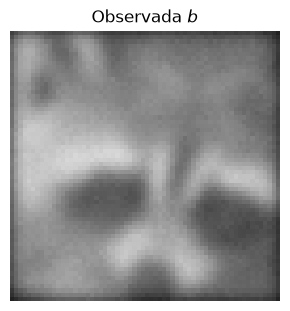

In [3]:
def mostrar(imagenes, titulos, archivo=None):
    fig, axs = plt.subplots(1, len(imagenes), figsize=(3 * len(imagenes), 3.2))
    axs = np.atleast_1d(axs)
    for ax, v, t in zip(axs, imagenes, titulos):
        ax.imshow(v.reshape(N, N), cmap="gray", vmin=0, vmax=1)
        ax.set_title(t)
        ax.axis("off")
    fig.tight_layout()
    if archivo is not None:
        fig.savefig(os.path.join("figuras", archivo), dpi=200, bbox_inches="tight")
    plt.show()


mostrar([b], ["Observada $b$"], archivo="ejemplo_b.png")

## (a) Mínimos cuadrados


## (b) Reconstrucción

### i. Implementación

***** Resultados *****
Norma de x0: 3.503e+05
Máximo absoluto de x0: 1.871e+04
Residuo: 5.626e-12


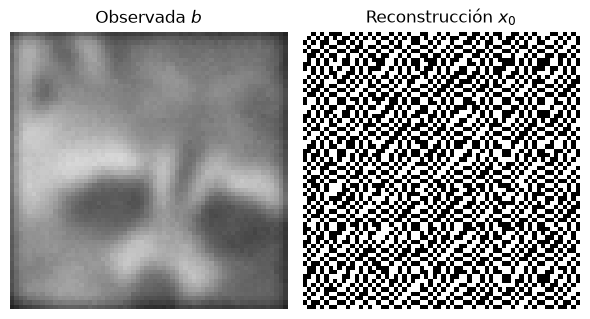

In [4]:
x0 = np.linalg.solve(A, b)
norma_x0 = np.linalg.norm(x0)
max_x0 = np.max(np.abs(x0))
residuo_x0 = np.linalg.norm(np.dot(A, x0) - b)

print("***** Resultados *****")
print(f"Norma de x0: {norma_x0:.4g}")
print(f"Máximo absoluto de x0: {max_x0:.4g}")
print(f"Residuo: {residuo_x0:.4g}")

mostrar([b, x0], ["Observada $b$", "Reconstrucción $x_0$"], archivo="reconstruccion_b.png")


## (c) Regularización de Tikhonov

### iv. Implementación

***** Resultados Lambda: 10^(-3.5)
Norma: 37.06
Residuo: 0.5617

***** Resultados Lambda: 10^(-2.5)
Norma: 36.02
Residuo: 0.6169

***** Resultados Lambda: 1
Norma: 17.18
Residuo: 17.85



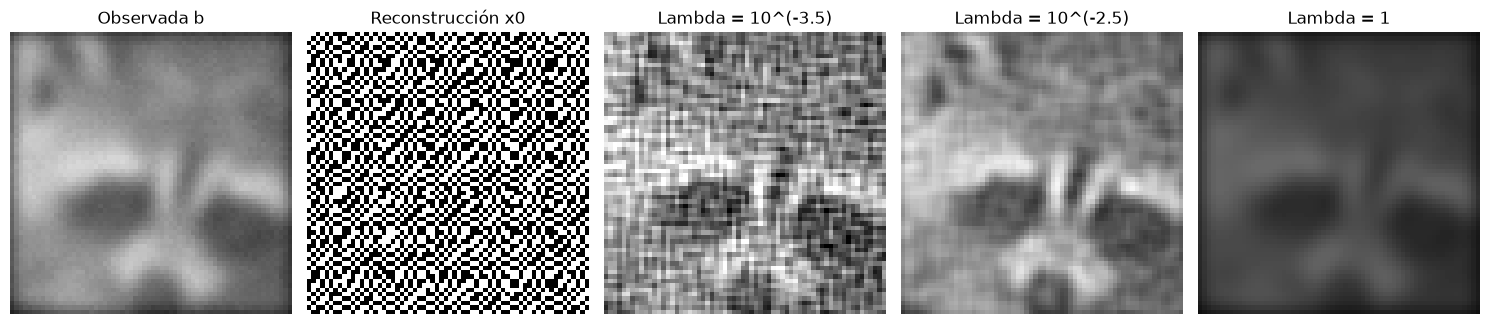

In [5]:
lambdas = [10**(-3.5), 10**(-2.5), 1]
lambdas_str = ["10^(-3.5)", "10^(-2.5)", "1"]
matriz_I = np.eye(n)

reconstrucciones = []

for valor_lambda in lambdas:
    imagen_reconstruida = np.linalg.solve(
        np.dot(A.T, A) + valor_lambda * matriz_I, np.dot(A.T, b))
    reconstrucciones.append(imagen_reconstruida)

for i in range(len(lambdas)):
    imagen = reconstrucciones[i]

    norma = np.linalg.norm(imagen)
    residuo = np.linalg.norm(np.dot(A, imagen) - b)

    print(f"***** Resultados Lambda: {lambdas_str[i]}")
    print(f"Norma: {norma:.4g}")
    print(f"Residuo: {residuo:.4g}\n")

mostrar(
    [b, x0, reconstrucciones[0], reconstrucciones[1], reconstrucciones[2]],
    ["Observada b", "Reconstrucción x0", "Lambda = 10^(-3.5)", "Lambda = 10^(-2.5)", "Lambda = 1"],
    archivo="reconstrucciones_tikhonov.png")

## (d) Píxeles dañados

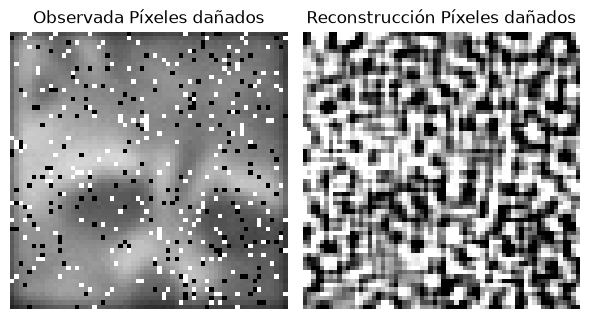

In [6]:
imagen_def = np.linalg.solve(
                        np.dot(A.T, A) + lambdas[1] * matriz_I,
                        np.dot(A.T, b_def))

mostrar(
    [b_def, imagen_def], ["Observada Píxeles dañados", "Reconstrucción Píxeles dañados"],
    archivo="reconstruccion_danada.png")


### ii. $\|\tilde{b} - b\|_2$

In [7]:
dif_observaciones = np.linalg.norm(b_def - b)

print("***** Resultados *****")
print(f"Norma de la diferencia: {dif_observaciones:.4g}")
print(f"Delta: {delta:.4g}")

***** Resultados *****
Norma de la diferencia: 10.74
Delta: 0.64
